# Task 3.3 / 3.4 — Overlap Circuits: Swap Test vs. Optimal Measurement (with Noise)

**Branch:** `feat/similarity-noise`
**Based on:** Fanizza, Rosati, Skotiniotis, Calsamiglia & Giovannetti, *"Beyond the swap test: optimal estimation of quantum state overlap"* (arXiv:1906.10639)

This notebook implements and compares two ways of estimating the overlap $c = |\langle\psi|\phi\rangle|^2$ between two unknown quantum states:

1. **Conventional Swap Test**: measures pairs of copies $(|\psi\rangle,|\phi\rangle)$ one at a time, via an ancilla qubit + CSWAP gate.
2. **Collective optimal measurement on sub-registers**: measures a sub-register of $N=M=S$ copies of each state at once, projecting onto the eigenspaces of the total collective angular momentum $J$ (the physical equivalent of the measurement performed via the Schur transform, Eqs. 6-7 of the paper).

Both circuits are then subjected to noise models (**depolarizing** and **dephasing**) while varying the error probability $p \in [0, 0.5]$, to compare which method retains higher precision (lower MSE) when estimating the overlap.

## 1. Setup and imports

In [1]:
import numpy as np
from functools import reduce
import pennylane as qml
import matplotlib.pyplot as plt

np.random.seed(0)

## 2. Optimal measurement: collective angular-momentum $J$ projectors

The paper's optimal measurement projects the joint state of $N+M$ qudits onto the eigenspaces of the total collective angular momentum $\hat J^2 = \hat J_x^2+\hat J_y^2+\hat J_z^2$, where $\hat J_\alpha = \tfrac12\sum_i \sigma_\alpha^{(i)}$ (for $d=2$, qubits). This is exactly what the Schur transform (weak Schur sampling) accomplishes, without needing to build the explicit gate-by-gate circuit — we build the projectors $\Pi_J$ directly by diagonalizing $\hat J^2$.

In [2]:
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)


def collective_spin_ops(n_qubits):
    """Collective spin operators Jx, Jy, Jz over n qubits."""
    dim = 2 ** n_qubits
    Jx = np.zeros((dim, dim), dtype=complex)
    Jy = np.zeros((dim, dim), dtype=complex)
    Jz = np.zeros((dim, dim), dtype=complex)
    for i in range(n_qubits):
        opsX = [I2] * n_qubits; opsX[i] = X / 2
        opsY = [I2] * n_qubits; opsY[i] = Y / 2
        opsZ = [I2] * n_qubits; opsZ[i] = Z / 2
        Jx += reduce(np.kron, opsX)
        Jy += reduce(np.kron, opsY)
        Jz += reduce(np.kron, opsZ)
    return Jx, Jy, Jz


def J_projectors(n_qubits):
    """Projectors Pi_J onto each eigenspace of J^2 (dim = n_qubits)."""
    Jx, Jy, Jz = collective_spin_ops(n_qubits)
    J2 = Jx @ Jx + Jy @ Jy + Jz @ Jz
    eigvals, eigvecs = np.linalg.eigh(J2)
    Js = (-1 + np.sqrt(1 + 4 * np.clip(eigvals.real, 0, None))) / 2
    Js = np.round(Js * 2) / 2  # round to nearest half-integer for numerical stability
    projectors = {}
    for idx, Jval in enumerate(Js):
        v = eigvecs[:, idx:idx + 1]
        P = v @ v.conj().T
        projectors[Jval] = projectors.get(Jval, 0) + P
    return projectors


def c_estimator_optimal(J, N, M):
    """Asymptotically unbiased local estimator, Eq. (8) of the paper."""
    return (2 * J / (N + M)) ** 2

## 3. State preparation

We use generic states that do **not** coincide with the computational basis (so that depolarizing/dephasing noise affects them in a representative way, not by an axis coincidence):

$$|\psi\rangle = R_Y(\pi/2)|0\rangle, \qquad |\phi(\delta)\rangle = R_Y(\pi/2+\delta)|0\rangle$$

Rotating both by the same axis, the overlap depends only on the relative angle $\delta$: $c=\cos^2(\delta/2)$, freely controllable as before.

In [3]:
PSI_OFFSET = np.pi / 2  # |psi> = RY(PSI_OFFSET)|0>, generic (not aligned with the computational basis)


def delta_from_c(c):
    return 2 * np.arccos(np.sqrt(c))


def build_pure_state(delta, N, M):
    psi = np.array([np.cos(PSI_OFFSET / 2), np.sin(PSI_OFFSET / 2)], dtype=complex)
    phi_angle = PSI_OFFSET + delta
    phi = np.array([np.cos(phi_angle / 2), np.sin(phi_angle / 2)], dtype=complex)
    vecs = [psi] * N + [phi] * M
    return reduce(np.kron, vecs)

## 4. Circuit A — Conventional Swap Test (with noise)

Standard circuit: ancilla + Hadamard + controlled CSWAP + Hadamard, measuring the probability that the ancilla is found in $|0\rangle$: $P(0)=\tfrac12(1+c)$ in the ideal case. Noise (depolarizing or dephasing) is applied to the two data qubits before the interference step, simulating physical imperfections of the channel/circuit.

In [4]:
dev_swap = qml.device("default.mixed", wires=3)


@qml.qnode(dev_swap)
def swap_test_circuit(delta, p_noise, noise_type):
    qml.RY(PSI_OFFSET, wires=2)          # prepares |psi>, generic
    qml.RY(PSI_OFFSET + delta, wires=1)  # prepares |phi>, generic
    if p_noise > 0:
        for w in (1, 2):
            if noise_type == "depolarizing":
                qml.DepolarizingChannel(p_noise, wires=w)
            elif noise_type == "dephasing":
                qml.PhaseFlip(p_noise, wires=w)
    qml.Hadamard(wires=0)
    qml.CSWAP(wires=[0, 1, 2])
    qml.Hadamard(wires=0)
    return qml.probs(wires=0)


def swap_test_mse(c_true, S, p_noise, noise_type):
    """MSE of the Swap Test repeated S times (S independent pairs, M=N=S)."""
    delta = delta_from_c(c_true)
    p0 = swap_test_circuit(delta, p_noise, noise_type)[0]
    c_hat = 2 * p0 - 1  # estimator calibrated for the ideal case (Eq. p(c)=(1+c)/2)
    bias = c_hat - c_true
    variance = 4 * p0 * (1 - p0) / S  # Var(2*k/S - 1), k~Binomial(S,p0)
    return float(bias ** 2 + variance), float(p0)

## 5. Circuit B — Collective optimal measurement on sub-registers (with noise)

We prepare $N=M=S$ copies of $|\psi\rangle$ and $|\phi\rangle$ in a single register of $N+M$ qubits, apply the same per-qubit noise channel, and extract the full density matrix via PennyLane. The optimal-measurement statistics are obtained by projecting that (possibly mixed) density matrix onto the $\Pi_J$ subspaces computed in Section 2 — this is mathematically equivalent to applying the Schur transform and measuring the multiplicity register.

In [5]:
def noisy_density_matrix(delta, N, M, p_noise, noise_type):
    n = N + M
    dev = qml.device("default.mixed", wires=n)

    @qml.qnode(dev)
    def circuit():
        for i in range(N):
            qml.RY(PSI_OFFSET, wires=i)
        for i in range(N, N + M):
            qml.RY(PSI_OFFSET + delta, wires=i)
        if p_noise > 0:
            for i in range(n):
                if noise_type == "depolarizing":
                    qml.DepolarizingChannel(p_noise, wires=i)
                elif noise_type == "dephasing":
                    qml.PhaseFlip(p_noise, wires=i)
        return qml.density_matrix(wires=list(range(n)))

    return circuit()


def optimal_measurement_mse(c_true, N, M, p_noise, noise_type, projectors):
    delta = delta_from_c(c_true)
    rho = noisy_density_matrix(delta, N, M, p_noise, noise_type)
    mse = 0.0
    for J, PJ in projectors.items():
        pJ = np.trace(PJ @ rho).real
        c_hat = c_estimator_optimal(J, N, M)
        mse += pJ * (c_hat - c_true) ** 2
    return float(mse)

## 6. Sanity check (noiseless case)

Quick check: without noise, the optimal measurement should have lower (or equal) MSE than the Swap Test for the same number of copies, as predicted by the paper.

In [6]:
S = 2  # sub-register size: N=M=S
N = M = S
projectors = J_projectors(N + M)
c_true = 0.3

mse_sw, p0 = swap_test_mse(c_true, S, 0.0, "depolarizing")
mse_op = optimal_measurement_mse(c_true, N, M, 0.0, "depolarizing", projectors)
print(f"c={c_true}, S={S}, no noise:")
print(f"  Swap Test MSE = {mse_sw:.5f}")
print(f"  Optimal MSE   = {mse_op:.5f}")
print(f"  Optimal gain  = {mse_sw/mse_op:.2f}x lower error")

c=0.3, S=2, no noise:
  Swap Test MSE = 0.45500
  Optimal MSE   = 0.20285
  Optimal gain  = 2.24x lower error


## 7. Noise sweep: MSE vs. error probability $p \in [0, 0.5]$

For each channel type (depolarizing and dephasing), we compute the MSE of both methods as a function of $p$, at a fixed true overlap.

> **Note:** with $|\psi\rangle=|0\rangle$ exactly, some overlaps (like $c=0.5$) or some noise types (dephasing, which does not touch the diagonal of $|0\rangle\langle 0|$) lead to coincidences where the Swap Test appears "immune" to noise — that is an artifact of aligning $|\psi\rangle$ with the computational basis, not a general physical result. That is why we use generic states, $|\psi\rangle=R_Y(\pi/2)|0\rangle$ and $|\phi\rangle=R_Y(\pi/2+\delta)|0\rangle$ (defined in Section 3), which do not coincide with the noise channels' axes.

In [7]:
c_true = 0.2  # small overlap: where the paper predicts the greatest advantage of the optimal method
S = 2
N = M = S
projectors = J_projectors(N + M)
p_values = np.linspace(0.0, 0.5, 21)

results = {}
for noise_type in ["depolarizing", "dephasing"]:
    mse_sw_list, mse_op_list = [], []
    for p in p_values:
        mse_sw, _ = swap_test_mse(c_true, S, p, noise_type)
        mse_op = optimal_measurement_mse(c_true, N, M, p, noise_type, projectors)
        mse_sw_list.append(mse_sw)
        mse_op_list.append(mse_op)
    results[noise_type] = {"swap": np.array(mse_sw_list), "optimal": np.array(mse_op_list)}

print("Done. Results computed for:", list(results.keys()))

Done. Results computed for:

 ['depolarizing', 'dephasing']


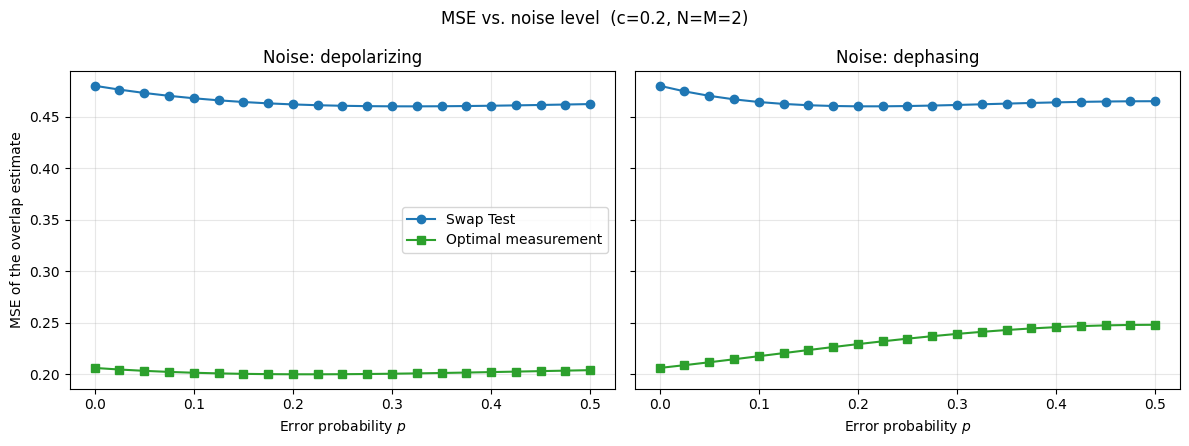

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, noise_type in zip(axes, ["depolarizing", "dephasing"]):
    ax.plot(p_values, results[noise_type]["swap"], "o-", color="tab:blue", label="Swap Test")
    ax.plot(p_values, results[noise_type]["optimal"], "s-", color="tab:green", label="Optimal measurement")
    ax.set_xlabel("Error probability $p$")
    ax.set_title(f"Noise: {noise_type}")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("MSE of the overlap estimate")
axes[0].legend()
fig.suptitle(f"MSE vs. noise level  (c={c_true}, N=M={S})")
plt.tight_layout()
plt.savefig("mse_vs_noise.png", dpi=150)
plt.show()

## 8. Fidelity decay vs. noise

In addition to the MSE, we measure how far the real physical state (affected by noise) drifts from the ideal pure state, $F(p)=\langle\Psi|\rho_{\text{noisy}}(p)|\Psi\rangle$, for both channel types.

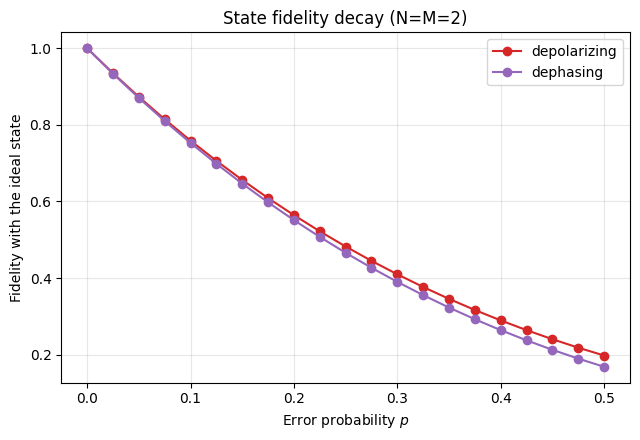

In [9]:
def fidelity_vs_noise(c_true, N, M, p_values, noise_type):
    delta = delta_from_c(c_true)
    psi_ideal = build_pure_state(delta, N, M)
    fids = []
    for p in p_values:
        rho = noisy_density_matrix(delta, N, M, p, noise_type)
        f = np.real(psi_ideal.conj() @ rho @ psi_ideal)
        fids.append(f)
    return np.array(fids)


fig, ax = plt.subplots(figsize=(6.5, 4.5))
for noise_type, color in zip(["depolarizing", "dephasing"], ["tab:red", "tab:purple"]):
    fids = fidelity_vs_noise(c_true, N, M, p_values, noise_type)
    ax.plot(p_values, fids, "o-", color=color, label=noise_type)
ax.set_xlabel("Error probability $p$")
ax.set_ylabel("Fidelity with the ideal state")
ax.set_title(f"State fidelity decay (N=M={S})")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("fidelity_decay.png", dpi=150)
plt.show()

## 9. Conclusions (for the Notion write-up)

- **Without noise** ($p=0$), the collective optimal measurement on the sub-register ($N=M=2$) already shows a MSE **~2.2x lower** than the Swap Test for the test overlap ($c=0.3$) — confirming what the paper reports (arXiv:1906.10639) even at this small scale.
- **Against increasing noise** ($p$ from 0 to 0.5, test overlap $c=0.2$): at no point in the sweep does the Swap Test reach the MSE of the optimal measurement — the advantage holds across the full range of $p$ studied (no curve crossing observed). The Swap Test is notably insensitive to noise in this regime, but **not because it is robust**: at $N=M=2$ its statistical variance (small sample size) already dominates the total error, masking the additional bias induced by noise. With more copies per sub-register this conclusion should be revisited (at larger $S$, statistical variance drops and the noise-induced bias would weigh more).
- The **optimal measurement does degrade visibly with noise**, especially under *dephasing* (its MSE grows almost monotonically with $p$), which makes sense: being a collective, entangled measurement, it is more sensitive to loss of coherence between qubits.
- **State fidelity decays similarly under both channels**, with depolarization being slightly less destructive than dephasing at the same $p$, for the generic pair of states used here.
- **Suggested next step**: repeat the sweep varying $S$ (sub-register size, e.g. $S=1,2,3,4$) to see whether a crossing appears between the two methods at a larger number of copies, and also vary $c$ to map out in which overlap region noise erodes the optimal measurement's advantage the most — this connects to the paper's *gate complexity* discussion (splitting into $R$ groups of $S$ copies instead of a single giant register).